In [170]:
import xarray as xr

In [171]:
import sys
sys.path.append('/nird/home/rguilcas/code/CyclonePrecipXAI/scripts')  # Add the src directory to the Python path

from aifsanalysis.plotting import TriPlotAccessor
import cartopy.feature as cfeat

from aifsanalysis.data import get_pressure_era5, get_surface_era5
from aifsanalysis.gridoperations import regrid_to_lonlat

# Download ERA5 rainfall data for winter

In [172]:
import io
import gcsfs
import xarray as xr
fs = gcsfs.GCSFileSystem(token="anon")

def open_raw(year, month, day, variable):
    path = (f"gcp-public-data-arco-era5/raw/date-variable-single_level/"
            f"{year}/{month:02d}/{day:02d}/{variable}/surface.nc")
    with fs.open(path, "rb") as f:
        return xr.open_dataset(io.BytesIO(f.read()), engine="scipy")

lsm = open_raw(2023, 1, 1, "land_sea_mask")["lsm"].isel(time=0, drop=True)
land = (lsm.sel(latitude=slice(80, 30)) >= 0.5).load()     # True over land


def get_precip_day_NH(year, month, day, lat_max=80, lat_min=30, land_mask=land):
    path = (f"gcp-public-data-arco-era5/raw/date-variable-single_level/"
            f"{year}/{month:02d}/{day:02d}/total_precipitation/surface.nc")
    with fs.open(path, "rb") as f:
        buf = io.BytesIO(f.read())                      # one download of the whole file
    ds = xr.open_dataset(buf, engine="scipy")
    tp = ds["tp"].sel(latitude=slice(lat_max, lat_min))#.where(land_mask)
    if 'valid_time' in tp.coords:
        tp = tp.sum("valid_time", min_count=1) * 1000   # mm/day
    else:
        tp = tp.sum("time", min_count=1) * 1000 
    return tp.load()



In [ ]:
from concurrent.futures import ThreadPoolExecutor
import pandas as pd
from tqdm.notebook import tqdm 

def get_day(date):
    tp = get_precip_day_NH(date.year, date.month, date.day)
    return tp.expand_dims(time=[date])   # mask ocean, label the day

all_winters = []
for year in [2023,2024,2025]:
    dates = pd.date_range(f"{year}-09-01", f"{year+1}-02-28", freq="D")
    with ThreadPoolExecutor(max_workers=32) as pool:
        days = list(tqdm(pool.map(get_day, dates), total=len(dates)))
    tp = xr.concat(days, dim="time")
    all_winters.append(tp)

tp = xr.concat(all_winters, dim='time').isel(expver=0)
tp.attrs['unit'] = 'mm/day'
tp.to_netcdf('/nird/datapeak/NS12107K/rguilcas/data/tp_daily_winter_2023-2025_Nh_30_80.nc')

land.to_netcdf('/nird/datapeak/NS12107K/rguilcas/data/era5_saeland_mask_Nh_30_80.nc')

  0%|          | 0/181 [00:00<?, ?it/s]

  0%|          | 0/181 [00:00<?, ?it/s]

  0%|          | 0/181 [00:00<?, ?it/s]

# Find rain objects

In [178]:
tp_land = tp.where(land)

In [192]:
from scipy.ndimage import label
import matplotlib.pyplot as plt

In [224]:
da

<xarray.DataArray 'tp' (latitude: 201, longitude: 1440)> Size: 2MB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]], shape=(201, 1440))
Coordinates:
  * latitude   (latitude) float32 804B 80.0 79.75 79.5 79.25 ... 30.5 30.25 30.0
  * longitude  (longitude) float32 6kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
    time       datetime64[us] 8B 2023-09-01
    expver     int32 4B 1
Attributes:
    units:      m
    long_name:  Total precipitation
    unit:       mm/day

<GeoAxes: title={'center': 'time = 2024-10-01, expver = 1'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

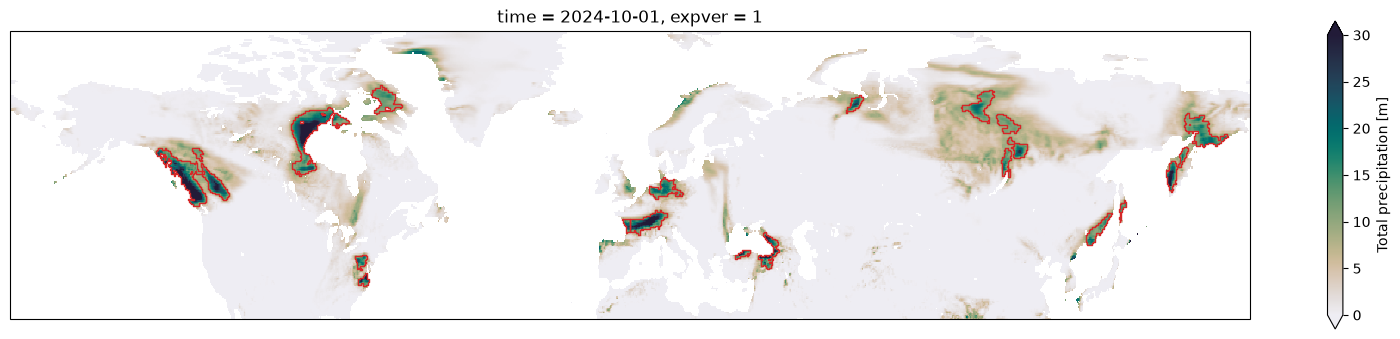

In [ ]:
from gdf_tools import labels_to_gdf
from scipy.ndimage import label

da = tp_land.sel(time='2024-10-01')
mask = da>10
labels = xr.ones_like(da)*label(mask)[0]
gdf = labels_to_gdf(labels)
gdf


# labels.plot()
plot = da.plot(subplot_kws=dict(projection=ccrs.PlateCarree()), aspect=5, size=4, vmax=30, vmin=0, cmap=cmo.rain)
gdf.query('area_km2>20000').plot(ax=plot.axes, transform=ccrs.PlateCarree(), edgecolor='tab:red', facecolor='none')

<xarray.DataArray 'time' (time: 543)> Size: 4kB
array(['2023-09-01T00:00:00.000000', '2023-09-02T00:00:00.000000',
       '2023-09-03T00:00:00.000000', ..., '2026-02-26T00:00:00.000000',
       '2026-02-27T00:00:00.000000', '2026-02-28T00:00:00.000000'],
      shape=(543,), dtype='datetime64[us]')
Coordinates:
  * time     (time) datetime64[us] 4kB 2023-09-01 2023-09-02 ... 2026-02-28
    expver   int32 4B 1

In [363]:
date

"<xarray.DataArray 'year' ()> Size: 8B\narray(2023)\nCoordinates:\n    time     datetime64[us] 8B 2023-09-01\n    expver   int32 4B 1-<xarray.DataArray 'month' ()> Size: 8B\narray(9)\nCoordinates:\n    time     datetime64[us] 8B 2023-09-01\n    expver   int32 4B 1-<xarray.DataArray 'day' ()> Size: 8B\narray(1)\nCoordinates:\n    time     datetime64[us] 8B 2023-09-01\n    expver   int32 4B 1"

In [374]:
date_

<xarray.DataArray 'tp' (latitude: 201, longitude: 1440)> Size: 2MB
array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       ...,
       [0.15092569, 0.2490274 , 0.22387311, ..., 0.02683123, 0.11151732,
        0.18781864],
       [0.02180038, 0.02850819, 0.04108533, ..., 0.27250473, 0.29514358,
        0.02180038],
       [0.        , 0.0033539 , 0.00251543, ..., 0.56177898, 0.39156833,
        0.04276228]], shape=(201, 1440))
Coordinates:
  * latitude   (latitude) float32 804B 80.0 79.75 79.5 79.25 ... 30.5 30.25 30.0
  * longitude  (longitude) float32 6kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
    time       datetime64[us] 8B 2024-01-01
    expver     int32 4B 1
Attributes:
    units:      m
    long_name:  Total precipitation
    unit:       mm/day

In [427]:
import numpy as np
import pandas as pd
from scipy.ndimage import label
from tqdm.notebook import tqdm
from gdf_tools import labels_to_gdf

CYC_DIR = "/nird/datapeak/NS12107K/rguilcas/data/cyclones_cnect"
STRUCT = np.ones((3, 3))          # 8-connectivity, same as labels_to_gdf and SAL
R_FIXED_KM = 1335                 # 12 deg, Hawcroft-style
MASK_FACTOR = 1.5                 # x storm radius, mask-style

def unit_vec(lat, lon):
    la, lo = np.deg2rad(lat), np.deg2rad(lon)
    return np.stack([np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)], -1)

_cyc_cache = {}
def load_cyclones(year, month):
    if (year, month) not in _cyc_cache:
        df = pd.read_csv(f"{CYC_DIR}/{year}/System13_2E5R_BBox10_{year}{month:02d}.csv")
        df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
        # TODO: apply track filters here (lifetime/length per sid, primary centres only)
        _cyc_cache[(year, month)] = df
    return _cyc_cache[(year, month)]

def day_points(day):
    nxt = day + pd.Timedelta(days=1)
    df = load_cyclones(day.year, day.month)
    if nxt.month != day.month:
        df = pd.concat([df, load_cyclones(nxt.year, nxt.month)])
    return df[(df["datetime"] >= day) & (df["datetime"] <= nxt)]      # this day only

all_events = []
for t in tqdm(tp_land.time.sel(time=slice("2024-01-01", "2025-12-31")).values):
    day = pd.Timestamp(t)
    da = tp_land.sel(time=day)

    lab_arr, n = label((da > 10).values, structure=STRUCT)
    if n == 0:
        continue
    labels = da.copy(data=lab_arr)
    gdf = labels_to_gdf(labels, values=da).query("area_km2 > 20000").copy()
    if gdf.empty:
        continue
    gdf["date"] = day

    pts = day_points(day)
    LA, LO = np.meshgrid(labels.latitude.values, labels.longitude.values, indexing="ij")
    cells = np.isin(lab_arr, gdf.index.values)                        # kept objects only
    lab = lab_arr[cells]
    w = da.values[cells] * np.cos(np.deg2rad(LA[cells]))              # rain x area weight

    if len(pts):
        cvec = unit_vec(pts["lat"].values, pts["lon"].values)
        dist = np.arccos(np.clip(unit_vec(LA[cells], LO[cells]) @ cvec.T, -1, 1)) * 6371.0
        near_fixed = (dist <= R_FIXED_KM).any(axis=1)
        near_mask = (dist <= MASK_FACTOR * pts["radius"].values[None, :]).any(axis=1)

        # nearest storm to each object's rain-weighted centre
        dc = np.arccos(np.clip(unit_vec(gdf["wcentre_lat"].values, gdf["wcentre_lon"].values)
                               @ cvec.T, -1, 1)) * 6371.0
        gdf["sid"] = pts["sid"].values[dc.argmin(axis=1)]
        gdf["dist_nearest_km"] = dc.min(axis=1)
        gdf["dist_nearest_radii"] = dc.min(axis=1) / pts["radius"].values[dc.argmin(axis=1)]
    else:
        near_fixed = near_mask = np.zeros(lab.size, dtype=bool)
        gdf["sid"], gdf["dist_nearest_km"], gdf["dist_nearest_radii"] = np.nan, np.inf, np.inf

    wsum = pd.Series(w).groupby(lab).sum()
    gdf["cyc_share_12deg"] = pd.Series(w * near_fixed).groupby(lab).sum() / wsum
    gdf["cyc_share_mask"] = pd.Series(w * near_mask).groupby(lab).sum() / wsum

    all_events.append(gdf)
    break

all_events = pd.concat(all_events)

  0%|          | 0/362 [00:00<?, ?it/s]

In [430]:
gdf

,geometry,n_cells,area_km2,centroid_lon,centroid_lat,mean,max,wcentre_lat,wcentre_lon,date,sid,dist_nearest_km,dist_nearest_radii,cyc_share_12deg,cyc_share_mask
label,,,,,,,,,,,,,,,
7,"POLYGON ((343.875 66.375, 343.875 66.125, 343....",135,44638.253354,-16.551741,64.811984,26.321645,56.109142,64.711604,343.836571,2024-01-01,34,1325.576987,1.002981,0.603237,1.000000
9,"POLYGON ((9.625 60.625, 9.625 60.375, 9.125 60...",105,41693.025778,9.594917,59.248205,19.043526,44.938964,59.159842,9.391237,2024-01-01,1,411.342526,29.163426,1.000000,1.000000
13,"POLYGON ((203.375 57.375, 203.375 57.125, 201....",54,23305.300196,-159.575745,56.219789,24.494961,45.141875,56.112282,200.244570,2024-01-01,5,430.230563,0.966510,1.000000,1.000000
17,"POLYGON ((351.625 55.125, 351.625 54.875, 351....",109,50376.531607,-7.525798,53.395396,12.162681,15.975485,53.368550,352.477807,2024-01-01,1,543.672195,0.765114,1.000000,1.000000
18,"POLYGON ((20.875 54.875, 20.875 54.375, 21.125...",415,200951.265768,23.688926,51.315117,12.637540,17.353101,51.321413,23.672591,2024-01-01,20,75.911113,0.406838,1.000000,0.888798
20,"POLYGON ((356.375 54.625, 356.375 54.375, 356....",213,101196.732443,-2.395986,52.194041,14.045419,23.703719,52.208087,357.463511,2024-01-01,1,387.593394,0.545463,1.000000,1.000000
23,"POLYGON ((229.625 54.125, 229.625 53.375, 230....",62,28813.916254,-128.521507,53.196482,16.485316,27.066008,53.149596,231.490117,2024-01-01,5,1745.679151,2.606310,0.000000,0.000000
30,"POLYGON ((358.125 49.625, 358.125 49.375, 358....",66,34183.080798,-2.188921,48.051739,12.158128,18.457374,48.054848,357.691049,2024-01-01,1,823.674349,1.159163,1.000000,1.000000
32,"POLYGON ((16.375 47.625, 16.375 47.375, 15.875...",113,60460.946754,15.433289,46.295739,13.424317,22.804034,46.274848,15.346097,2024-01-01,20,591.702486,41.950614,1.000000,0.000000


In [426]:
all_events

,geometry,n_cells,area_km2,centroid_lon,centroid_lat,mean,max,wcentre_lat,wcentre_lon,date,sid,dist_nearest_km,dist_nearest_radii,cyc_share_12deg,cyc_share_mask
label,,,,,,,,,,,,,,,
7,"POLYGON ((343.875 66.375, 343.875 66.125, 343....",135,44638.253354,-16.551741,64.811984,26.321645,56.109142,64.711604,343.836571,2024-01-01,34,1325.576987,1.002981,0.603237,1.000000
9,"POLYGON ((9.625 60.625, 9.625 60.375, 9.125 60...",105,41693.025778,9.594917,59.248205,19.043526,44.938964,59.159842,9.391237,2024-01-01,1,411.342526,29.163426,1.000000,1.000000
13,"POLYGON ((203.375 57.375, 203.375 57.125, 201....",54,23305.300196,-159.575745,56.219789,24.494961,45.141875,56.112282,200.244570,2024-01-01,5,430.230563,0.966510,1.000000,1.000000
17,"POLYGON ((351.625 55.125, 351.625 54.875, 351....",109,50376.531607,-7.525798,53.395396,12.162681,15.975485,53.368550,352.477807,2024-01-01,1,543.672195,0.765114,1.000000,1.000000
18,"POLYGON ((20.875 54.875, 20.875 54.375, 21.125...",415,200951.265768,23.688926,51.315117,12.637540,17.353101,51.321413,23.672591,2024-01-01,20,75.911113,0.406838,1.000000,0.888798
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42,"POLYGON ((140.125 39.625, 140.125 39.375, 139....",35,21401.185522,138.925257,37.714479,13.703527,22.843051,37.704398,138.920370,2025-12-30,626,4885.258166,17.001937,0.000000,0.000000
47,"POLYGON ((53.875 37.375, 53.875 37.125, 54.125...",34,21112.095875,53.527791,36.549352,15.187046,25.985735,36.535292,53.448242,2025-12-30,626,3245.801323,8.271540,0.000000,0.000000
50,"POLYGON ((74.125 36.375, 74.125 35.625, 74.625...",331,213212.006476,68.637118,33.418019,16.446385,39.055824,33.384050,68.455003,2025-12-30,626,3355.643005,8.551459,0.000000,0.000000


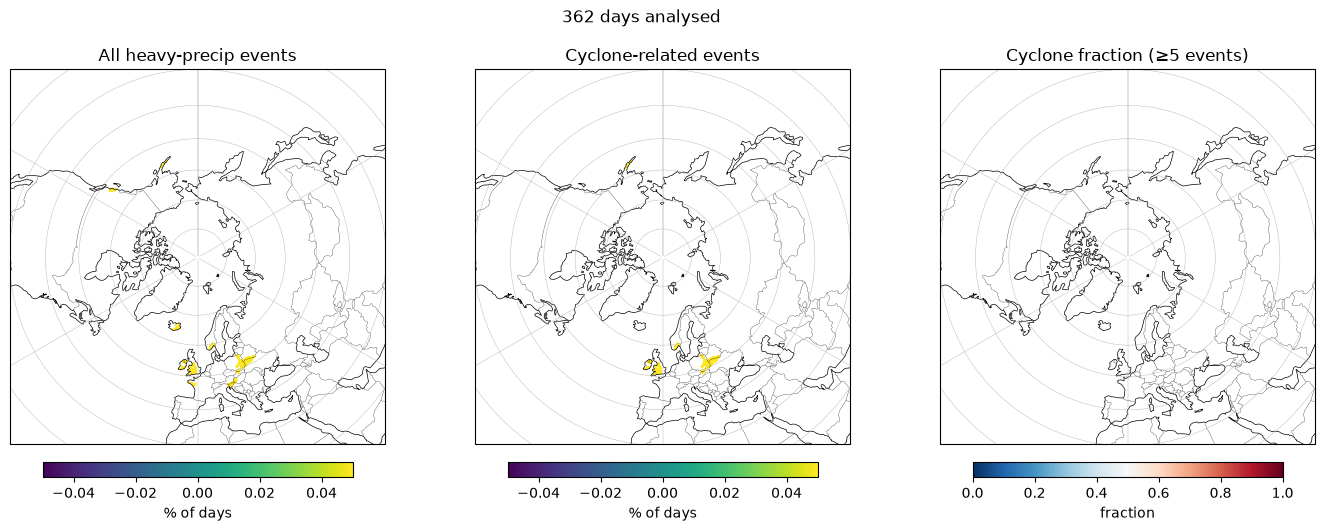

In [425]:
# from gdf_tools import plot_event_frequency
freq = event_frequency(all_event, n_days=362)
plot = plot_event_frequency(freq)



In [402]:
"""
Frequency maps of heavy-precipitation events from a GeoDataFrame of event polygons.

    from event_density import event_frequency, plot_event_frequency
    freq = event_frequency(all_events, n_days=n_days_analysed)
    plot_event_frequency(freq)

Each polygon is burnt back onto the 0.25 deg grid and counted, so a grid cell's value
is the number of days it was inside a heavy-precipitation event. Polygons from
labels_to_gdf follow grid-cell edges, so this recovers the original cells exactly.
"""

import numpy as np
import xarray as xr
from rasterio.features import rasterize, MergeAlg
from rasterio.transform import from_origin
from shapely.affinity import translate
from shapely.geometry import box
import shapely


def _to_180(geom):
    """Bring a polygon into -180..180, splitting it if it crosses 180 (works for inputs
    in 0..360 or -180..180)."""
    minx, _, maxx, _ = geom.bounds
    if minx >= -180 and maxx <= 180:
        return geom
    parts = [geom.intersection(box(-180, -90, 180, 90)),
             translate(geom.intersection(box(180, -90, 540, 90)), xoff=-360),
             translate(geom.intersection(box(-540, -90, -180, 90)), xoff=360)]
    return shapely.union_all([p for p in parts if not p.is_empty])


def _count(geoms, lat_min, lat_max, lon_min, res):
    nlat = int(round((lat_max - lat_min) / res)) + 1
    nlon = int(round(360 / res))
    transform = from_origin(lon_min - res / 2, lat_max + res / 2, res, res)
    if len(geoms) == 0:
        return np.zeros((nlat, nlon), dtype=np.int32)
    return rasterize(((g, 1) for g in geoms), out_shape=(nlat, nlon), transform=transform,
                     merge_alg=MergeAlg.add, fill=0, dtype="int32")


def event_frequency(events, n_days, flag="cyclone_related", lat_min=30.0, lat_max=80.0,
                    res=0.25):
    """Returns a Dataset with, per grid cell:
       n_events / n_cyclone     number of event days (all / cyclone-related)
       freq / freq_cyclone      event days per 100 analysed days
       cyclone_fraction         share of event days that are cyclone-related
    n_days: number of days ANALYSED (including days without events), for normalising.
    Polygons may use 0..360 or -180..180 longitudes; the output grid is -180..180."""
    lon_min = -180.0
    geoms = np.array([_to_180(g) for g in events.geometry], dtype=object)
    is_cyc = events[flag].astype(bool).values
    n_all = _count(list(geoms), lat_min, lat_max, lon_min, res)
    n_cyc = _count(list(geoms[is_cyc]), lat_min, lat_max, lon_min, res)

    lat = lat_max - res * np.arange(n_all.shape[0])
    lon = lon_min + res * np.arange(n_all.shape[1])
    ds = xr.Dataset(
        {"n_events": (["latitude", "longitude"], n_all),
         "n_cyclone": (["latitude", "longitude"], n_cyc)},
        coords={"latitude": lat, "longitude": lon},
    )
    ds["freq"] = 100 * ds.n_events / n_days
    ds["freq_cyclone"] = 100 * ds.n_cyclone / n_days
    ds["cyclone_fraction"] = (ds.n_cyclone / ds.n_events).where(ds.n_events > 0)
    ds["freq"].attrs["units"] = ds["freq_cyclone"].attrs["units"] = "% of days"
    ds.attrs["n_days"] = n_days
    return ds


def plot_event_frequency(freq, min_events=5, vmax=None):
    """Three polar panels: all events, cyclone-related events, cyclone fraction.
    The fraction is shown only where a cell had at least `min_events` events."""
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    import matplotlib.pyplot as plt

    proj = ccrs.NorthPolarStereo()
    fig, axes = plt.subplots(1, 3, figsize=(17, 6), subplot_kw={"projection": proj})
    vmax = vmax or float(freq.freq.quantile(0.995))
    panels = [
        (freq.freq.where(freq.n_events > 0), "All heavy-precip events",
         dict(cmap="viridis", vmin=0, vmax=vmax), "% of days"),
        (freq.freq_cyclone.where(freq.n_cyclone > 0), "Cyclone-related events",
         dict(cmap="viridis", vmin=0, vmax=vmax), "% of days"),
        (freq.cyclone_fraction.where(freq.n_events >= min_events),
         f"Cyclone fraction (≥{min_events} events)",
         dict(cmap="RdBu_r", vmin=0, vmax=1), "fraction"),
    ]
    for ax, (da, title, kw, label) in zip(axes, panels):
        ax.set_extent([-180, 180, float(freq.latitude.min()), 90], ccrs.PlateCarree())
        im = da.plot(ax=ax, transform=ccrs.PlateCarree(), add_colorbar=False, **kw)
        ax.coastlines(linewidth=0.5)
        ax.add_feature(cfeature.BORDERS, linewidth=0.2)
        ax.gridlines(linewidth=0.3)
        ax.set_title(title)
        fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.8, pad=0.04, label=label)
    fig.suptitle(f"{freq.attrs.get('n_days', '?')} days analysed")
    return fig

(np.float64(-7383278.156871644),
 np.float64(7383278.156871644),
 np.float64(-8400840.39684526),
 np.float64(7383278.156871644))

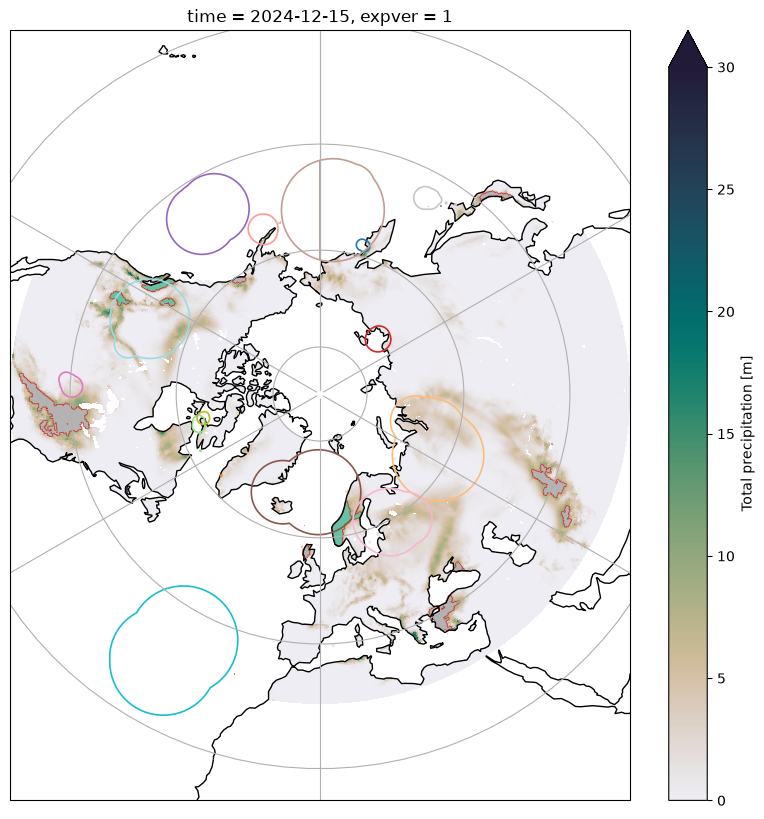

In [357]:

# labels.plot()
plot = da.plot(subplot_kws=dict(projection=ccrs.NorthPolarStereo()), aspect=1, size=10, vmax=30, vmin=0, cmap=cmo.rain, transform=ccrs.PlateCarree())
gdf.query('area_km2>20000').plot(ax=plot.axes, transform=ccrs.PlateCarree(), edgecolor='tab:red', facecolor='none')

footprints.assign(geometry=footprints.boundary).plot(
    ax=plot.axes, column="sid", categorical=True, cmap="tab20",
    linewidth=1.2, transform=ccrs.PlateCarree(),
)
# plt.legend()
gdf.plot(column="cyclone_related", categorical=True, cmap="Set2_r",ax=plot.axes, transform=ccrs.PlateCarree())

plot.axes.coastlines()
gl = plot.axes.gridlines()
plt.axis('equal')

In [ ]:
ea = "EPSG:6933"
obj = gdf.to_crs(ea)
fp = footprints.to_crs(ea)
inter = gpd.overlay(obj.reset_index(), fp, how="intersection")
inter["overlap_km2"] = inter.area / 1e6
frac = inter.groupby(["label", "sid"])["overlap_km2"].sum() / obj["area_km2"]
best = frac.groupby("label").max()               # best-matching storm per object
gdf["cyc_frac"] = best.reindex(gdf.index).fillna(0)
gdf["cyclone_related"] = gdf["cyc_frac"] >= 0.5
best_sid = frac.groupby(level="label").idxmax().map(lambda t: t[1])   # (label, sid) -> sid
gdf["sid"] = best_sid.reindex(gdf.index)             # NaN if no overlap

<Axes: >

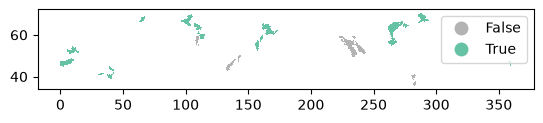

In [333]:
gdf.plot(column="cyclone_related", categorical=True, cmap="Set2_r",
         legend=True, )

<Axes: >

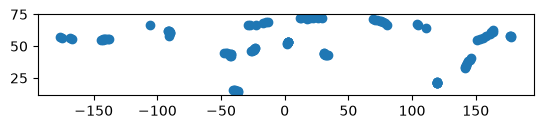

In [ ]:
gdf_cycs.loc['2024-10-01'].plot

(0.0, 10.0)

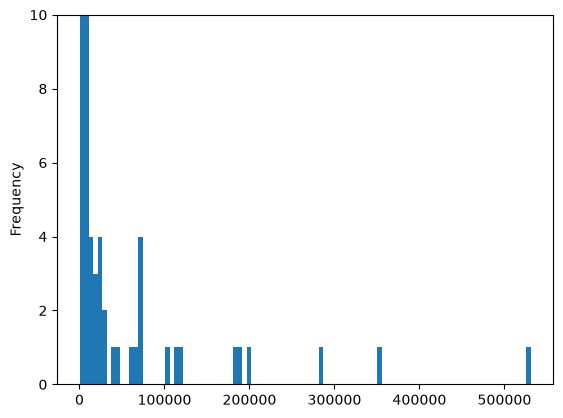

In [240]:
gdf.area_km2.plot.hist(bins=100)
plt.ylim(0,10)

In [ ]:
from gdf_tools import labels_to_gdf

gdf = labels_to_gdf(labels)
gdf

,geometry,n_cells,area_km2,centroid_lon,centroid_lat
label,,,,,
1,"POLYGON ((235.625 74.375, 235.625 73.875, 235....",208,47232.566795,-122.216822,73.004322
2,"POLYGON ((26.125 70.875, 26.125 70.625, 24.625...",637,180738.895039,26.784842,68.530618
3,"POLYGON ((317.375 70.375, 317.375 70.125, 316....",82,22420.126020,-42.901125,69.421723
4,"POLYGON ((170.625 70.125, 170.625 69.375, 172....",15,4051.096513,171.301059,69.697166
5,"POLYGON ((324.625 70.125, 324.625 69.875, 323....",908,282561.191142,-38.468755,66.033473
...,...,...,...,...,...
180,"POLYGON ((103.125 31.125, 103.125 30.875, 103....",2,1323.562249,103.375000,30.999920
181,"POLYGON ((249.125 30.875, 249.125 30.125, 249....",11,7331.704630,-110.408765,30.294555
182,"POLYGON ((244.625 30.625, 244.625 30.375, 244....",1,665.157510,-115.250000,30.499921


# Get cyclone
Crawford, Alex D; Serreze, Mark C; Barber, David; Dahl-Jensen, Dorthe; Stroeve, Julienne, 2021, “CEOS/NSIDC Extratropical Cyclone Tracking (CNECT)”, 10.34992/ebnw-s681, CanWIN, Version 13.2.

In [ ]:
df

In [27]:

tp = xr.concat(all_winters, dim='time').isel(expver=0)
tp.attrs['unit'] = 'mm/day'
tp.to_netcdf('/nird/datapeak/NS12107K/rguilcas/data/tp_daily_winter_2023-2025_Nh_30_80.nc')

In [ ]:




# (pr.sel(lead_time=lead_time, init_time=init_time).where(land_180)*21600).plot()

In [ ]:
import dynamical_catalog  # pip install "dynamical-catalog>=0.8.0"

ds = dynamical_catalog.open("ecmwf-aifs-single-forecast", chunks=None)
pr = ds["precipitation_surface"].sel(latitude=slice(80,30))#.where(land)  # rate, see units below

land_180 = land.assign_coords(longitude=land.longitude.where(land.longitude<180, land.longitude-360)).sortby('longitude')

time_of_event = pd.to_datetime('2024-10-01')

lead_times = pd.timedelta_range(start='1D', end ='14D', freq='6h')
init_times = time_of_event-lead_times

all_predictions = []
for k, lead_time in tqdm(enumerate(lead_times)):
    init_time = init_times[k]
    pr_prediction = pr.sel(lead_time=slice(lead_time,lead_time+pd.Timedelta(23,'h')), init_time=init_time).where(land_180).load().sum('lead_time',min_count=1)*21600
    all_predictions.append(pr_prediction)
ds_preds = xr.concat(all_predictions, dim='init_time')
ds_preds =ds_preds.sortby('init_time')

0it [00:00, ?it/s]

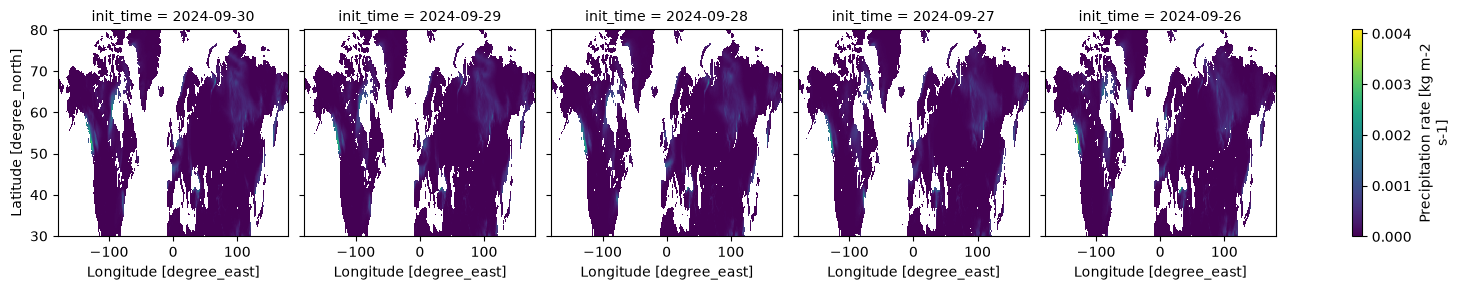

In [132]:
ds_preds.plot(col='init_time')

In [126]:
ds_truth = tp.sel(time=time_of_event)
ds_truth = ds_truth.assign_coords(longitude=ds_truth.longitude.where(ds_truth.longitude<180, ds_truth.longitude-360)).sortby('longitude')
# ds_preds = ds_preds.assign_coords(longitude=ds_preds.longitude.where(ds_preds.longitude<180, ds_preds.longitude-360)).sortby('longitude')

In [115]:
truth = ds_truth.where(ds_truth>20)
preds = ds_preds.where(truth.notnull()) 

# Alaskan event

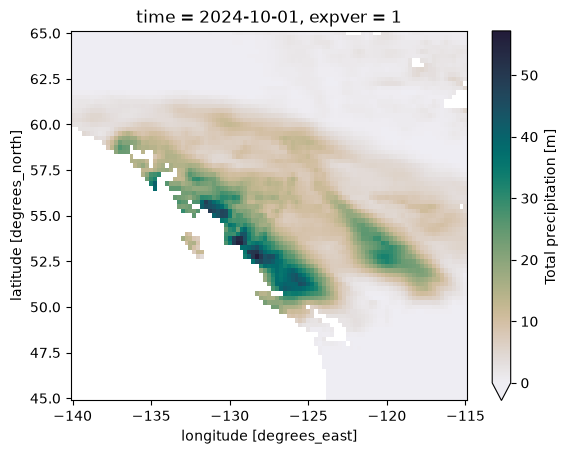

In [140]:
ds_truth.sel(longitude=slice(-140,-115), latitude=slice(65,45)).plot(cmap=cmo.rain, vmin=0)

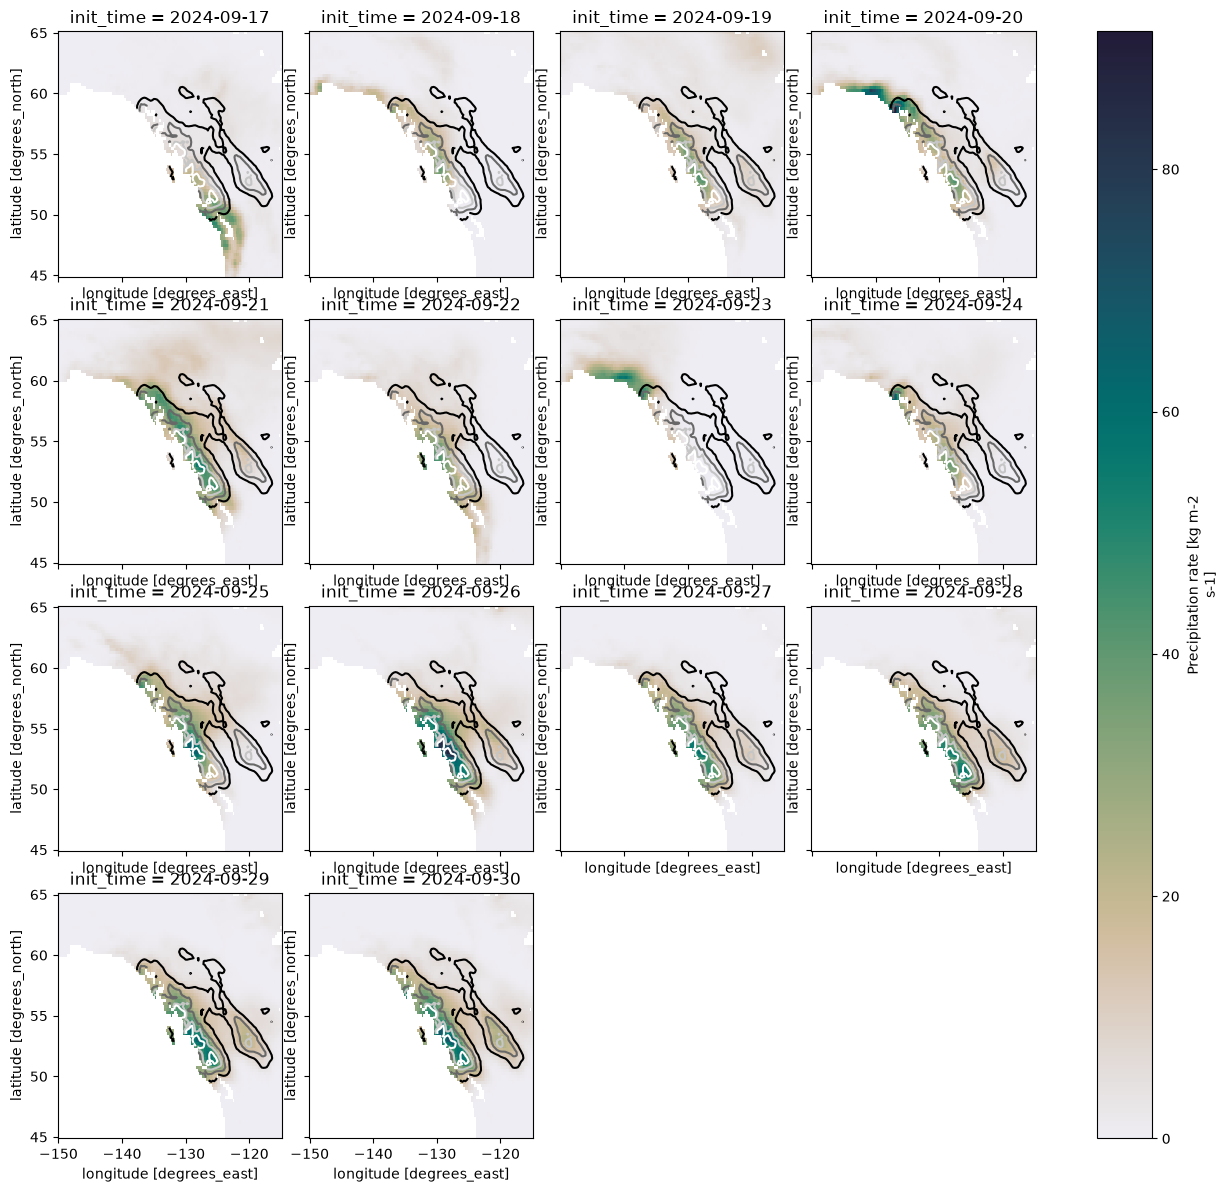

In [151]:
plot = ds_preds.sel(longitude=slice(-150,-115), latitude=slice(65,45)).plot(cmap=cmo.rain, vmin=0, col='init_time', col_wrap=4)
for ax in plot.axs.flat:
    title = ax.get_title()
    ds_truth.sel(longitude=slice(-140,-115), latitude=slice(65,45)).plot.contour(levels=[10,20,30,40], ax=ax, cmap='Greys_r')
    ax.set_title(title)

# other

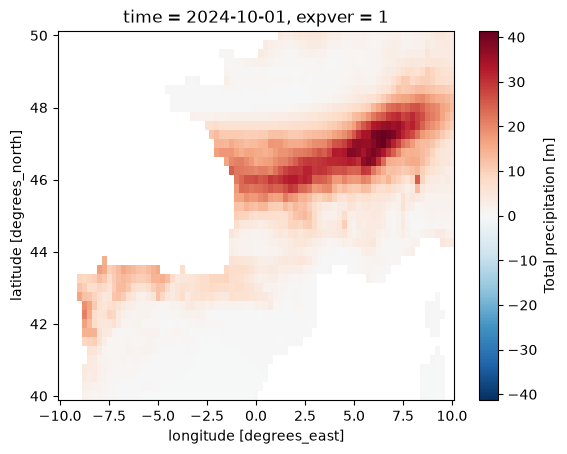

In [157]:
ds_truth.sel(longitude=slice(-10,10), latitude=slice(50,40)).plot()

<Axes: xlabel='init_time'>

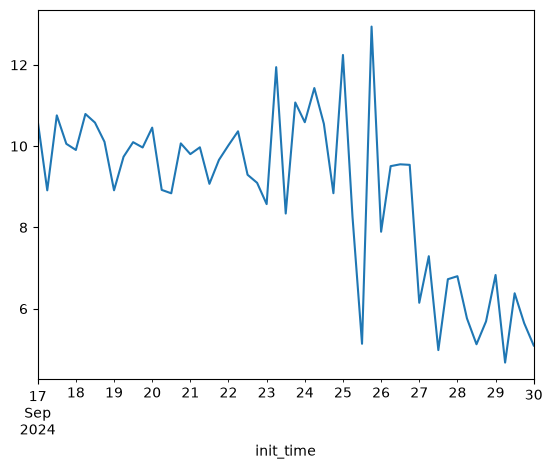

In [169]:
from event_metrics import event_metrics

df_fr = event_metrics(ds_preds.sel(longitude=slice(-10,10), latitude=slice(50,40)), ds_truth.sel(longitude=slice(-10,10), latitude=slice(50,40)))

df_fr.RMSE.plot()

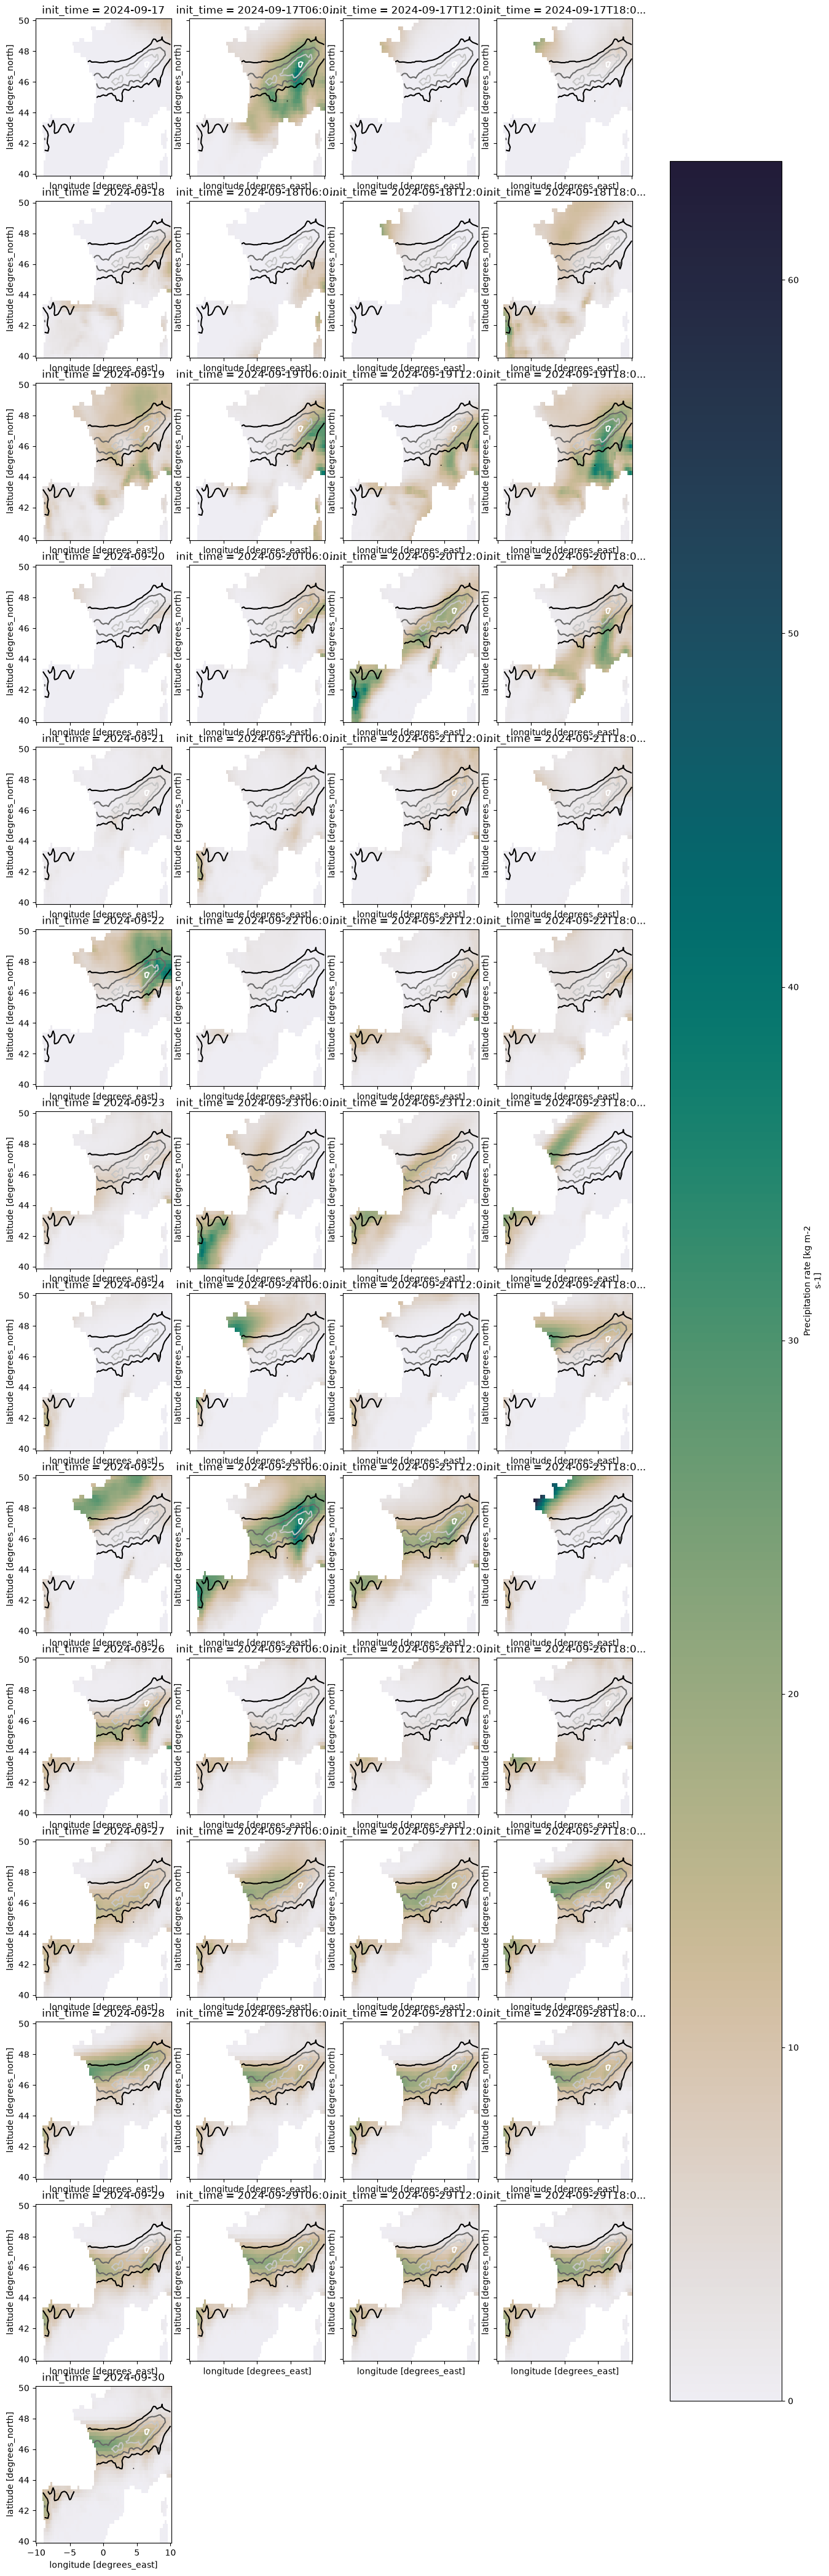

In [168]:
plot = ds_preds.sel(longitude=slice(-10,10), latitude=slice(50,40)).plot(cmap=cmo.rain, vmin=0, col='init_time', col_wrap=4)
for ax in plot.axs.flat:
    title = ax.get_title()
    ds_truth.sel(longitude=slice(-10,10), latitude=slice(50,40)).plot.contour(levels=[10,20,30,40], ax=ax, cmap='Greys_r')
    ax.set_title(title)

In [117]:
ds_preds.isel(lead_time=0).sel(longitude=slice(-140,-115), latitude=slice(65,45))#.plot()

<xarray.DataArray 'precipitation_surface' (latitude: 81, longitude: 0)> Size: 0B
array([], shape=(81, 0), dtype=float32)
Coordinates:
  * latitude                  (latitude) float64 648B 65.0 64.75 ... 45.25 45.0
  * longitude                 (longitude) float64 0B 
    lead_time                 timedelta64[us] 8B 1 days
    expected_forecast_length  timedelta64[us] 8B 15 days
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2024-09-30
    valid_time                datetime64[ns] 8B 2024-10-01
    spatial_ref               int64 8B 0
Attributes:
    long_name:      Precipitation rate
    short_name:     prate
    standard_name:  precipitation_flux
    units:          kg m-2 s-1
    comment:        Average precipitation rate since the previous forecast st...
    step_type:      avg

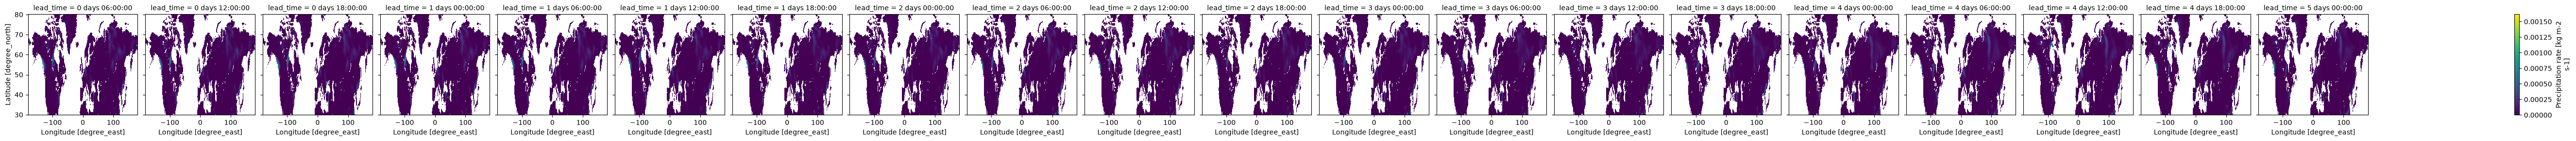

In [94]:
ds_preds.where(land_180).plot(col='lead_time')

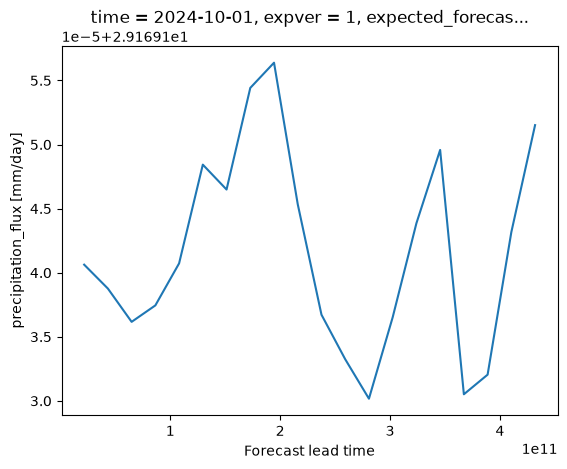

In [86]:
import numpy as np
np.sqrt(((truth-preds)**2).mean(['longitude','latitude'])).plot()

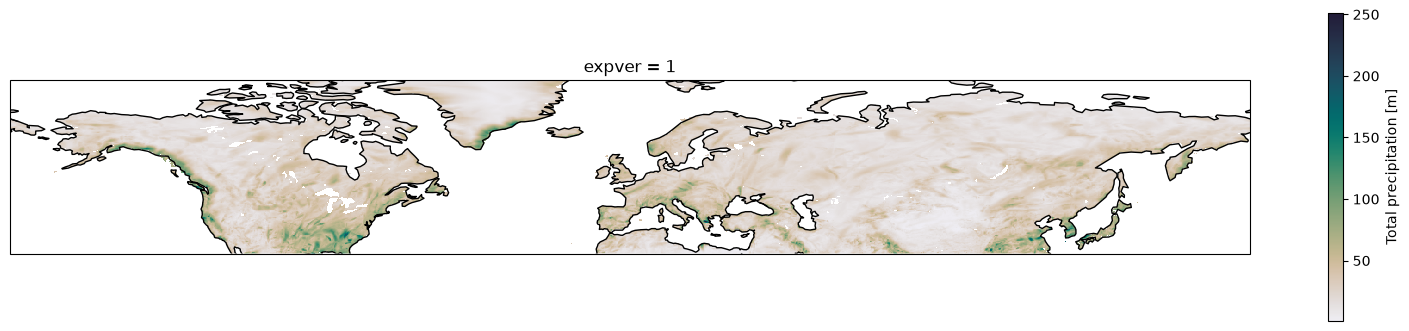

In [23]:
import cartopy.crs as ccrs
import cmocean.cm as cmo
plot = tp.max('time').plot(subplot_kws = dict(projection=ccrs.PlateCarree()),transform=ccrs.PlateCarree(), size=4, aspect=5, cmap=cmo.rain, vmax=None)
plot.axes.coastlines()

In [ ]:
tp.to_netcdf()

<xarray.DataArray 'tp' (time: 543, latitude: 201, longitude: 1440)> Size: 1GB
array([[[            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        [            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        [            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        ...,
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00]],

       [[            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        [            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        [            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
...
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00]],

       [[            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        [            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        [            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        ...,
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          2.46395577e-03,  1.64263718e-03,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          4.92791153e-03,  8.21318589e-04,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          1.64263718e-03,  0.00000000e+00,  0.00000000e+00]]],
      shape=(543, 201, 1440))
Coordinates:
  * time       (time) datetime64[us] 4kB 2023-09-01 2023-09-02 ... 2026-02-28
  * latitude   (latitude) float32 804B 80.0 79.75 79.5 79.25 ... 30.5 30.25 30.0
  * longitude  (longitude) float32 6kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
    expver     int32 4B 1
Attributes:
    units:      m
    long_name:  Total precipitation

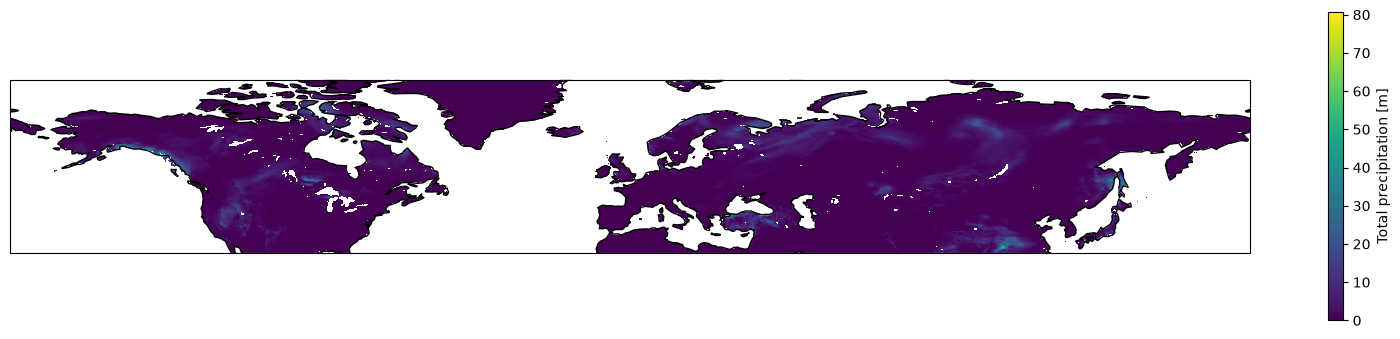

In [58]:
plot = tp.plot(subplot_kws=dict(projection=ccrs.PlateCarree()), size=4, aspect=5)
plot.axes.coastlines()

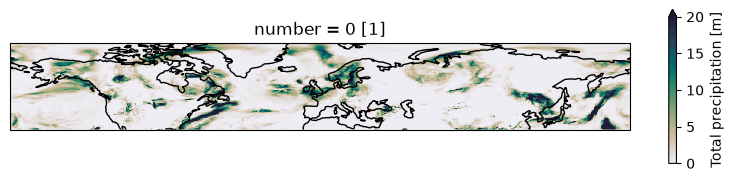

In [32]:
import cmocean.cm as cmo
import cartopy.crs as ccrs
plot = ds.plot(subplot_kws=dict(projection=ccrs.PlateCarree()), transform =ccrs.PlateCarree(), size=2, aspect=5, cmap=cmo.rain, vmax=20)
plot.axes.coastlines()


In [3]:
from dask.distributed import Client
client = Client()
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 8
Total threads: 32,Total memory: 35.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:46647,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:37701,Total threads: 4
Dashboard: http://127.0.0.1:40935/status,Memory: 4.38 GiB
Nanny: tcp://127.0.0.1:38251,


In [5]:
import numpy as np
import pandas as pd
import zarr

STORE = "gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3"
opts = {"token": "anon"}

tp = zarr.open_array(f"{STORE}/total_precipitation", mode="r", storage_options=opts)  # (time, lat, lon)
time_arr = zarr.open_array(f"{STORE}/time", mode="r", storage_options=opts)
print(tp.shape, tp.chunks, dict(time_arr.attrs))   # check the time units, e.g. "hours since 1900-01-01"

# t0 = pd.Timestamp(int(time_arr[0]), unit="h", origin="1900-01-01")  # adjust to the printed units

def hourly_index(t):
    return int((t - t0) / pd.Timedelta(hours=1))

(1323648, 721, 1440) (1, 721, 1440) {'_ARRAY_DIMENSIONS': ['time'], 'calendar': 'proleptic_gregorian', 'units': 'hours since 1900-01-01 00:00:00'}


In [14]:
ds = xr.open_zarr(
    "gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3",
    chunks={}, storage_options={"token": "anon"},
)

In [ ]:
ds_test = ds['total_precipitation'].sel(time=slice('2023','2023')).sel(latitude=slice(80,50)).load()

2026-09-29 00:19:54,854 - distributed.worker - ERROR - Compute Failed
Key:       ('open_dataset-getitem-da0aaa85f08dcce89d8d17a46fa9c979', 966, 0, 0)
State:     executing
Task:  <Task ('open_dataset-getitem-da0aaa85f08dcce89d8d17a46fa9c979', 966, 0, 0) _execute_subgraph(...)>
Exception: 'RuntimeError("can\'t start new thread")'
Traceback: '  File "/nird/home/rguilcas/robin-env/lib/python3.12/site-packages/dask/array/core.py", line 140, in getter\n    c = np.asarray(c)\n        ^^^^^^^^^^^^^\n  File "/nird/home/rguilcas/robin-env/lib/python3.12/site-packages/xarray/core/indexing.py", line 691, in __array__\n    return np.asarray(to_numpy(self.get_duck_array()), dtype=dtype, copy=copy)\n                               ^^^^^^^^^^^^^^^^^^^^^\n  File "/nird/home/rguilcas/robin-env/lib/python3.12/site-packages/xarray/core/indexing.py", line 697, in get_duck_array\n    return self.array.get_duck_array()\n           ^^^^^^^^^^^^^^^^^^^^^^^^^^^\n  File "/nird/home/rguilcas/robin-env/lib/python3.

RuntimeError: can't start new thread

/nird/home/rguilcas/robin-env/lib/python3.12/site-packages/dask/sizeof.py:19: RuntimeWarning: coroutine 'AsyncArray._get_selection' was never awaited
  @sizeof.register(object)
